# Fase 3 — Análisis predictivo: informalidad laboral juvenil en Paraguay
**Data Science — Proyecto Integrador · Cuaderno 03 de 03 · Grupo 5 · Universidad Nacional de Asunción**

| | |
|---|---|
| **Orden de ejecución** | Tercer cuaderno. Requiere `data/processed/dataset_limpio.csv` (cuaderno 01, versionado en el repositorio). |
| **Salidas** | `output/fase3/tabla_resultados_fase3.csv`, `tabla_validacion_fase3.csv`, figuras en `output/fase3/figuras/` y modelos en `output/fase3/modelos/` |
| **Tiempo** | ≈ 2 minutos (búsqueda en grilla de 9 combinaciones con validación temporal) |

**Pregunta de investigación (Fase 1).** ¿Qué factores se asocian con la informalidad laboral de las personas ocupadas no agropecuarias de 18 a 29 años en Paraguay (2024-T1 a 2026-T2)?

**Tarea predictiva.** Clasificación binaria: predecir `informal` (1 = informal) de cada persona ocupada a partir de atributos individuales, del puesto y del hogar. Responde a los objetivos específicos predictivos de la Fase 1 y usa las variables que la Fase 2 dejó como candidatas.

### Correcciones aplicadas a la Fase 2
Este cuaderno incorpora las limitaciones que la propia Fase 2 declaró: (i) circularidad posible entre `tam_empresa` y la definición INE de informalidad → se entrena con y sin esa variable; (ii) dependencia por hogar → partición y validación agrupadas por hogar; (iii) Hosmer-Lemeshow rechazó el ajuste → se evalúa calibración explícitamente; (iv) `ingreso` e `ingreso_hora` quedan excluidas por fuga de información.

### Declaración de uso de IA
Se empleó un asistente de IA (Claude) para redactar código y estructura del cuaderno. Las decisiones metodológicas (variables, diseño de partición, criterios de selección) y la interpretación son del grupo, que revisó y comprende todo el código.

## 0. Configuración y carga

In [1]:
# ==========================================================================================
# CELDA 0 · Preparación del entorno (ejecutar siempre primero)
#   · Google Colab: clona el repositorio en /content y se ubica en notebooks/.
#   · Local (Jupyter o VS Code): no descarga nada; usa la copia local del repositorio.
# ==========================================================================================
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/rlop026/informalidad-laboral-juvenil.git"   # repositorio del proyecto en GitHub
VERSIONES_EXACTAS = False   # True: instala requirements.txt (mismas versiones que los resultados publicados)
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    destino = Path("/content/informalidad-laboral-juvenil")
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(destino)], check=True)
    os.chdir(destino / "notebooks")
    if VERSIONES_EXACTAS:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(destino / "requirements.txt")], check=True)
        print("Versiones instaladas: reiniciá la sesión (Entorno de ejecución > Reiniciar) y volvé a ejecutar desde aquí.")

# Raíz del repositorio = carpeta que contiene src/entorno.py; se agrega src/ al path de importación
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "entorno.py").exists()), None)
if RAIZ is None:
    raise FileNotFoundError("Abrí este cuaderno desde la carpeta notebooks/ del repositorio.")
sys.path.insert(0, str(RAIZ / "src"))
print("Entorno:", "Google Colab" if EN_COLAB else "local", "· raíz del proyecto:", RAIZ)

Entorno: local · raíz del proyecto: informalidad-laboral-juvenil


In [2]:
import re, sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, brier_score_loss, confusion_matrix, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid", font_scale=0.95)
AZUL, NARANJA, GRIS = "#1F4E79", "#E07A3F", "#7F7F7F"
print("scikit-learn", sklearn.__version__)

from IPython.display import display
from entorno import rutas, guardar_figura

R = rutas("fase3")
RUTA_SRC = R["raiz"] / "src"                          # features.py y predict.py
RUTA_DATOS = R["processed"] / "dataset_limpio.csv"   # salida del cuaderno 01 (Fase 1)
RUTA_OUT, RUTA_FIG, RUTA_MOD = R["out"], R["fig"], R["modelos"]
# Módulo compartido con el script de inferencia (src/features.py)
from features import preparar, NUM, CAT_BASE, TRAMOS
df_raw = pd.read_csv(RUTA_DATOS, encoding="utf-8-sig")

# Auditoría contra la Fase 1 / Fase 2: si algo no coincide, el cuaderno se detiene
req = ["informal","ID_HOGAR","periodo","tam_empresa","ocupacion","educ_nivel","educ_anios","edad","mujer","rural",
       "entorno_informal","clima_educativo"]
assert not [c for c in req if c not in df_raw.columns], f"Faltan columnas: {[c for c in req if c not in df_raw.columns]}"
chk = {"filas = 12.691": len(df_raw)==12691, "hogares = 10.055": df_raw.ID_HOGAR.nunique()==10055,
       "tasa sin ponderar ≈ 71,2 %": abs(df_raw.informal.mean()-0.712)<0.001}
for k,v in chk.items(): print("✓" if v else "✗", k)
assert all(chk.values()), "El dataset no coincide con el de las Fases 1 y 2"

scikit-learn 1.8.0
✓ filas = 12.691
✓ hogares = 10.055
✓ tasa sin ponderar ≈ 71,2 %


## 1. Definición de la tarea y variables
- **Objetivo:** `informal` (0/1). Clasificación. Prevalencia ≈ 71 % → la **exactitud sola no es aceptable**; se reportan matriz de confusión, precisión, exhaustividad, F1, AUC-ROC y exactitud balanceada.
- **Variables candidatas (Fase 2):** `tam_empresa`, `ocupacion` (agrupada), `educ_nivel`, `educ_anios`, `entorno_informal`, `clima_educativo`, `mujer`, `rural`, `edad`; y las no contrastadas `rama`, `horas`, `antiguedad`, `departamento`.
- **Excluidas:** `ingreso`, `ingreso_hora` (consecuencia de la informalidad, H4 → fuga); `factor`, IDs; `periodo` como predictor (con partición cronológica el modelo nunca vería 2026 en entrenamiento, así que no puede aprender un efecto de esos trimestres).
- **Tres conjuntos de variables**, definidos antes de modelar:
  - **A — completo.**
  - **B — sin `tam_empresa`**: controla el riesgo de circularidad con la definición INE (Fase 2, §4.1).
  - **C — sin `tam_empresa` ni `entorno_informal`**: variables observables sin conocer la condición laboral de otras personas del hogar; es la versión realmente «desplegable» para estimar informalidad de una persona aislada.

In [3]:
df = preparar(df_raw)
y_all = df["informal"].astype(int)

CAT_TAM, CAT_ENT = ["tam_cat"], ["entorno_informal"]
NUM_OK = [c for c in NUM if c in df.columns]
CAT_OK = [c for c in CAT_BASE if c in df.columns]
CONJUNTOS = {
    "A completo":            (NUM_OK, CAT_OK + CAT_TAM + CAT_ENT),
    "B sin tamaño":          (NUM_OK, CAT_OK + CAT_ENT),
    "C sin tamaño ni hogar": ([c for c in NUM_OK if c != "clima_educativo"], CAT_OK),
}
for k,(n,c) in CONJUNTOS.items(): print(f"{k}: {len(n)} numéricas + {len(c)} categóricas")
print("Columnas excluidas explícitamente:", [c for c in ["ingreso","ingreso_hora","factor","otros_informales"] if c in df.columns])

A completo: 7 numéricas + 6 categóricas
B sin tamaño: 7 numéricas + 5 categóricas
C sin tamaño ni hogar: 6 numéricas + 4 categóricas
Columnas excluidas explícitamente: ['ingreso', 'ingreso_hora', 'factor', 'otros_informales']


## 2. Partición cronológica y por hogar
Hay componente temporal, así que la partición **no es aleatoria**: se entrena con 2024-2025 (8 trimestres) y se prueba con 2026 (T1-T2). Además se quitan del entrenamiento los hogares que aparecen en prueba, para que miembros de un mismo hogar no queden a ambos lados. El conjunto de prueba **no se inspecciona** hasta la sección 7.

In [4]:
es_test = (df["anio"] >= 2026).values
test_hog = set(df.loc[es_test, "ID_HOGAR"])
mask_train = (~es_test) & (~df["ID_HOGAR"].isin(test_hog).values)
print(f"Entrenamiento 2024-2025: {mask_train.sum():,} filas ({df.loc[mask_train,'ID_HOGAR'].nunique():,} hogares)")
print(f"Prueba 2026:             {es_test.sum():,} filas ({len(test_hog):,} hogares)")
print(f"Filas de 2024-2025 descartadas por compartir hogar con prueba: {(~es_test).sum()-mask_train.sum():,}")
tr = df[mask_train].reset_index(drop=True); te = df[es_test].reset_index(drop=True)
ytr = tr["informal"].astype(int); yte = te["informal"].astype(int)   # yte se usa recién en la sección 7
prev = ytr.mean(); print(f"Prevalencia de informalidad en entrenamiento: {prev:.3f}")

Entrenamiento 2024-2025: 10,532 filas (8,344 hogares)
Prueba 2026:             2,159 filas (1,711 hogares)
Filas de 2024-2025 descartadas por compartir hogar con prueba: 0
Prevalencia de informalidad en entrenamiento: 0.714


## 3. Validación cruzada temporal agrupada por hogar
Forward-chaining sobre el entrenamiento: cada pliegue valida en **un trimestre** (los últimos 4 de 2024-2025) y entrena solo con trimestres **anteriores**, excluyendo hogares presentes en el trimestre de validación. Es la variante temporal de k-fold exigida; los hiperparámetros se ajustan solo con estos pliegues y **nunca con prueba**.

In [5]:
def folds_temporales(d, n_val=4):
    per = sorted(d.t_idx.unique()); out = []
    for p in per[-n_val:]:
        va = np.where(d.t_idx.values == p)[0]
        hog = set(d.ID_HOGAR.values[va])
        trn = np.where((d.t_idx.values < p) & (~d.ID_HOGAR.isin(hog).values))[0]
        out.append((trn, va))
    return out
FOLDS = folds_temporales(tr)
for i,(a,b) in enumerate(FOLDS,1): print(f"Pliegue {i}: entrena {len(a):,} · valida {len(b):,} (prevalencia val. {ytr.iloc[b].mean():.3f})")

Pliegue 1: entrena 6,082 · valida 1,014 (prevalencia val. 0.732)
Pliegue 2: entrena 7,096 · valida 1,038 (prevalencia val. 0.729)
Pliegue 3: entrena 8,134 · valida 1,106 (prevalencia val. 0.704)
Pliegue 4: entrena 9,240 · valida 1,292 (prevalencia val. 0.704)


## 4. Líneas base
Todo modelo debe superarlas:
1. **Clase mayoritaria** (predice «informal» siempre; exactitud = prevalencia, AUC = 0,5).
2. **Regla simple de tamaño** (hallazgo de la Fase 2): informal si el establecimiento es «Solo» o de «2 a 5» personas. Es una base más exigente que la trivial: mide cuánto agrega el aprendizaje automático sobre una regla de una línea.

In [6]:
def regla_tamano(d): return d["tam_empresa"].isin([1, 2]).astype(float).values
def metricas(y, p, thr=0.5):
    yh = (np.asarray(p) >= thr).astype(int); y = np.asarray(y)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0,1]).ravel()
    return {"AUC": roc_auc_score(y, p) if len(set(p))>1 else 0.5, "Exactitud": accuracy_score(y, yh),
            "Exact. balanc.": balanced_accuracy_score(y, yh), "Precisión": precision_score(y, yh, zero_division=0),
            "Exhaustividad": recall_score(y, yh, zero_division=0), "F1": f1_score(y, yh, zero_division=0),
            "Especificidad": tn/(tn+fp) if tn+fp else np.nan, "Brier": brier_score_loss(y, p)}
dummy = DummyClassifier(strategy="prior").fit(tr[["edad"]], ytr)
# (las líneas base se evalúan en train/validación acá y en prueba en la sección 7)
oof_idx = np.concatenate([b for _,b in FOLDS])
base_val = pd.DataFrame({"Mayoritaria": metricas(ytr.iloc[oof_idx], dummy.predict_proba(tr.iloc[oof_idx][["edad"]])[:,1]),
                         "Regla tamaño": metricas(ytr.iloc[oof_idx], regla_tamano(tr.iloc[oof_idx]))}).T
base_val.round(3)

,AUC,Exactitud,Exact. balanc.,Precisión,Exhaustividad,F1,Especificidad,Brier
Mayoritaria,0.500,0.716,0.500,0.716,1.000,0.835,0.000,0.203
Regla tamaño,0.686,0.634,0.686,0.880,0.567,0.689,0.804,0.366


## 5. Modelos, hiperparámetros y búsqueda en grilla
Tres familias: **regresión logística** (lineal, interpretable; vincula con los OR de la Fase 2), **Random Forest** (bagging de árboles) y **Gradient Boosting por histogramas** (boosting de árboles; captura interacciones como tamaño × ocupación). El preprocesamiento (imputación por mediana con indicador de faltante, escalado, one-hot) está **dentro del pipeline**, de modo que se ajusta solo con los datos de entrenamiento de cada pliegue. Los faltantes de `clima_educativo`, `horas` y `antiguedad` son estructurales (Fase 2) y se conservan con su indicador.

Métrica de selección: **AUC-ROC** (no depende del umbral ni de la prevalencia).

In [7]:
def make_pre(num, cat):
    try: ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError: ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
    return ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                                                ("sc", StandardScaler())]), num),
                              ("cat", ohe, cat)])
MODELOS = {
 "Logística": (LogisticRegression(max_iter=3000, random_state=SEMILLA),
               {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
 "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1),
               {"clf__max_depth": [6, 12, None], "clf__min_samples_leaf": [5, 20], "clf__class_weight": [None, "balanced"]}),
 "Boosting (HistGB)": (HistGradientBoostingClassifier(max_iter=200, random_state=SEMILLA),
               {"clf__learning_rate": [0.05, 0.1], "clf__max_leaf_nodes": [8, 31], "clf__l2_regularization": [0.0, 1.0]}),
}
GS = {}
for cj,(num,cat) in CONJUNTOS.items():
    X = tr[num+cat]
    for mn,(est,grid) in MODELOS.items():
        pipe = Pipeline([("pre", make_pre(num,cat)), ("clf", clone(est))])
        gs = GridSearchCV(pipe, grid, cv=FOLDS, scoring="roc_auc", refit=True, return_train_score=True, n_jobs=-1)
        GS[(cj,mn)] = gs.fit(X, ytr); print(f"✓ {cj} · {mn}: AUC val. {gs.best_score_:.4f}")

✓ A completo · Logística: AUC val. 0.8706


✓ A completo · Random Forest: AUC val. 0.8811


✓ A completo · Boosting (HistGB): AUC val. 0.8817


✓ B sin tamaño · Logística: AUC val. 0.8082


✓ B sin tamaño · Random Forest: AUC val. 0.8337


✓ B sin tamaño · Boosting (HistGB): AUC val. 0.8385


✓ C sin tamaño ni hogar · Logística: AUC val. 0.8029


✓ C sin tamaño ni hogar · Random Forest: AUC val. 0.8344


✓ C sin tamaño ni hogar · Boosting (HistGB): AUC val. 0.8340


### 5.1 Resultados de validación y sobreajuste (entrenamiento vs. validación)
La brecha `AUC entrenamiento − AUC validación` es el indicador de sobreajuste. Se reportan los hiperparámetros elegidos.

In [8]:
filas = []
for (cj,mn),gs in GS.items():
    i = gs.best_index_; r = gs.cv_results_
    filas.append({"Conjunto": cj, "Modelo": mn, "AUC entren.": r["mean_train_score"][i], "AUC valid.": r["mean_test_score"][i],
                  "± DE valid.": r["std_test_score"][i], "Brecha": r["mean_train_score"][i]-r["mean_test_score"][i],
                  "Hiperparámetros": {k.replace("clf__",""):v for k,v in gs.best_params_.items()}})
TAB_CV = pd.DataFrame(filas); TAB_CV.round(4)

,Conjunto,Modelo,AUC entren.,AUC valid.,± DE valid.,Brecha,Hiperparámetros
0,A completo,Logística,0.8756,0.8706,0.0076,0.0051,"{'C': 10, 'class_weight': 'balanced'}"
1,A completo,Random Forest,0.9498,0.8811,0.0056,0.0687,"{'class_weight': None, 'max_depth': None, 'min..."
2,A completo,Boosting (HistGB),0.9204,0.8817,0.0069,0.0387,"{'l2_regularization': 1.0, 'learning_rate': 0...."
3,B sin tamaño,Logística,0.8228,0.8082,0.0081,0.0146,"{'C': 0.1, 'class_weight': 'balanced'}"
4,B sin tamaño,Random Forest,0.9397,0.8337,0.0064,0.1059,"{'class_weight': 'balanced', 'max_depth': None..."
5,B sin tamaño,Boosting (HistGB),0.9356,0.8385,0.0105,0.0971,"{'l2_regularization': 1.0, 'learning_rate': 0...."
6,C sin tamaño ni hogar,Logística,0.8152,0.8029,0.0098,0.0123,"{'C': 0.1, 'class_weight': 'balanced'}"
7,C sin tamaño ni hogar,Random Forest,0.9156,0.8344,0.0097,0.0812,"{'class_weight': 'balanced', 'max_depth': None..."
8,C sin tamaño ni hogar,Boosting (HistGB),0.9176,0.8340,0.0135,0.0836,"{'l2_regularization': 1.0, 'learning_rate': 0...."


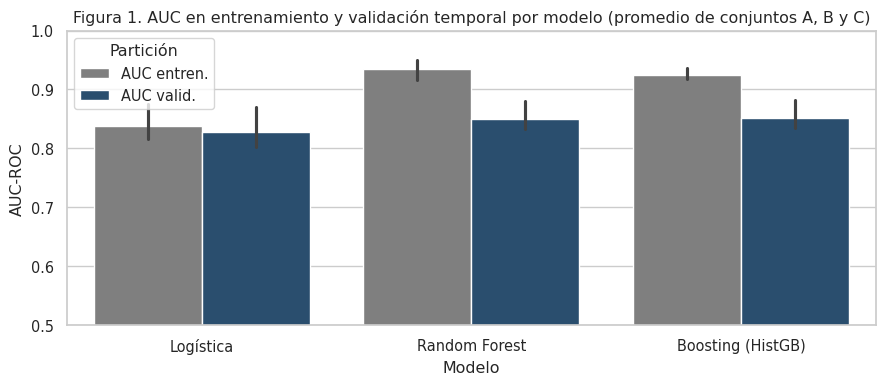

In [9]:
fig, ax = plt.subplots(figsize=(9,4))
p = TAB_CV.melt(id_vars=["Conjunto","Modelo"], value_vars=["AUC entren.","AUC valid."], var_name="Partición", value_name="AUC")
sns.barplot(data=p, x="Modelo", y="AUC", hue="Partición", ax=ax, palette=[GRIS, AZUL])
ax.set_ylim(0.5, 1.0); ax.set_title("Figura 1. AUC en entrenamiento y validación temporal por modelo (promedio de conjuntos A, B y C)")
ax.set_ylabel("AUC-ROC"); ax.set_xlabel("Modelo"); plt.tight_layout(); guardar_figura(RUTA_FIG, "fig1_auc_entrenamiento_validacion"); plt.show()

**Interpretación.** La brecha AUC entrenamiento − validación es mínima en la regresión logística (0,005 a 0,015), grande en el Random Forest, que eligió profundidad sin límite (0,069 a 0,106), e intermedia en el boosting del conjunto A (0,039); en B y C el boosting sube a 0,08–0,10, porque con menos señal memoriza más ruido. La logística eligió pesos balanceados en los tres conjuntos (C = 10 en A y C = 0,1 en B y C) y el boosting, regularización l2 = 1. El desvío del AUC entre los cuatro pliegues es bajo (0,006 a 0,014): el desempeño de validación es estable entre trimestres.

## 6. Umbral de decisión y desempeño fuera de muestra *en validación*
Las predicciones fuera de muestra (OOF) de los pliegues temporales sirven para elegir el **umbral** que maximiza la exactitud balanceada (la prevalencia de 71 % hace que 0,5 favorezca a la clase mayoritaria) y para elegir el **modelo finalista de cada conjunto** (mayor AUC OOF). Todo se decide acá, sin usar prueba.

In [10]:
def oof_probs(gs, X, y):
    p = np.full(len(y), np.nan)
    for a,b in FOLDS:
        m = clone(gs.best_estimator_).fit(X.iloc[a], y.iloc[a]); p[b] = m.predict_proba(X.iloc[b])[:,1]
    return p
def mejor_umbral(y, p):
    g = np.linspace(0.05, 0.95, 91); s = [balanced_accuracy_score(y, (p>=t).astype(int)) for t in g]; return float(g[int(np.argmax(s))])
OOF, UMBRAL, VAL = {}, {}, []
for (cj,mn),gs in GS.items():
    num,cat = CONJUNTOS[cj]; X = tr[num+cat]; p = oof_probs(gs, X, ytr)
    OOF[(cj,mn)] = p; UMBRAL[(cj,mn)] = mejor_umbral(ytr.iloc[oof_idx], p[oof_idx])
    VAL.append({"Conjunto":cj, "Modelo":mn, "Umbral":UMBRAL[(cj,mn)], **metricas(ytr.iloc[oof_idx], p[oof_idx], UMBRAL[(cj,mn)])})
VAL = pd.DataFrame(VAL)
FINALISTA = {cj: VAL[VAL.Conjunto==cj].sort_values("AUC", ascending=False).iloc[0]["Modelo"] for cj in CONJUNTOS}
print("Finalista por conjunto (según AUC de validación):", FINALISTA)
VAL.round(3)

Finalista por conjunto (según AUC de validación): {'A completo': 'Boosting (HistGB)', 'B sin tamaño': 'Boosting (HistGB)', 'C sin tamaño ni hogar': 'Boosting (HistGB)'}


,Conjunto,Modelo,Umbral,AUC,Exactitud,Exact. balanc.,Precisión,Exhaustividad,F1,Especificidad,Brier
0,A completo,Logística,0.52,0.870,0.791,0.794,0.909,0.788,0.844,0.801,0.143
1,A completo,Random Forest,0.68,0.880,0.799,0.805,0.917,0.792,0.850,0.819,0.127
2,A completo,Boosting (HistGB),0.77,0.882,0.782,0.805,0.930,0.751,0.831,0.858,0.122
3,B sin tamaño,Logística,0.54,0.808,0.723,0.740,0.888,0.702,0.784,0.778,0.176
4,B sin tamaño,Random Forest,0.57,0.834,0.747,0.765,0.904,0.724,0.804,0.806,0.156
5,B sin tamaño,Boosting (HistGB),0.78,0.839,0.736,0.768,0.917,0.694,0.790,0.842,0.143
6,C sin tamaño ni hogar,Logística,0.60,0.803,0.690,0.732,0.903,0.636,0.746,0.827,0.178
7,C sin tamaño ni hogar,Random Forest,0.55,0.835,0.743,0.762,0.903,0.719,0.800,0.806,0.159
8,C sin tamaño ni hogar,Boosting (HistGB),0.70,0.835,0.760,0.762,0.891,0.757,0.819,0.767,0.145


## 7. Evaluación final en el conjunto de prueba (una sola vez)
Esta es **la única celda que toca `yte`**. Se evalúan en un mismo paso las líneas base y los nueve modelos ya entrenados, con los hiperparámetros y umbrales fijados en las secciones 5 y 6. **Ninguna decisión posterior de modelado depende de estos resultados.** Se reportan entrenamiento (dentro de muestra), validación (OOF) y prueba para discutir la brecha.

In [11]:
filas = []
def fila(nombre, cj, ptr, pva, pte, thr):
    return {"Modelo": nombre, "Conjunto": cj, **{f"{k} (prueba)": v for k,v in metricas(yte, pte, thr).items()},
            "AUC entren.": roc_auc_score(ytr, ptr) if len(set(ptr))>1 else 0.5,
            "AUC valid.": roc_auc_score(ytr.iloc[oof_idx], pva) if len(set(pva))>1 else 0.5,
            "Exactitud entren.": accuracy_score(ytr, (ptr>=thr).astype(int)),
            "Exactitud valid.": accuracy_score(ytr.iloc[oof_idx], (pva>=thr).astype(int))}
# líneas base
pd_tr = dummy.predict_proba(tr[["edad"]])[:,1]; pd_te = dummy.predict_proba(te[["edad"]])[:,1]
filas.append(fila("Base: clase mayoritaria","—", pd_tr, pd_tr[oof_idx], pd_te, 0.5))
filas.append(fila("Base: regla de tamaño","—", regla_tamano(tr), regla_tamano(tr)[oof_idx], regla_tamano(te), 0.5))
PTE = {}
for (cj,mn),gs in GS.items():
    num,cat = CONJUNTOS[cj]; thr = UMBRAL[(cj,mn)]
    ptr = gs.best_estimator_.predict_proba(tr[num+cat])[:,1]
    pte = gs.best_estimator_.predict_proba(te[num+cat])[:,1]; PTE[(cj,mn)] = pte
    filas.append(fila(mn, cj, ptr, OOF[(cj,mn)][oof_idx], pte, thr))
TEST = pd.DataFrame(filas)
cols = ["Modelo","Conjunto","AUC (prueba)","Exactitud (prueba)","Exact. balanc. (prueba)","Precisión (prueba)","Exhaustividad (prueba)","F1 (prueba)","Brier (prueba)","AUC entren.","AUC valid."]
TEST[cols].round(3)

,Modelo,Conjunto,AUC (prueba),Exactitud (prueba),Exact. balanc. (prueba),Precisión (prueba),Exhaustividad (prueba),F1 (prueba),Brier (prueba),AUC entren.,AUC valid.
0,Base: clase mayoritaria,—,0.500,0.704,0.500,0.704,1.000,0.827,0.208,0.500,0.500
1,Base: regla de tamaño,—,0.687,0.646,0.687,0.868,0.587,0.700,0.354,0.680,0.686
2,Logística,A completo,0.880,0.798,0.798,0.904,0.798,0.847,0.137,0.874,0.870
3,Random Forest,A completo,0.892,0.812,0.816,0.917,0.806,0.858,0.124,0.947,0.880
4,Boosting (HistGB),A completo,0.896,0.789,0.814,0.935,0.752,0.834,0.119,0.898,0.882
5,Logística,B sin tamaño,0.811,0.720,0.731,0.874,0.704,0.780,0.175,0.819,0.808
6,Random Forest,B sin tamaño,0.851,0.747,0.766,0.902,0.719,0.800,0.151,0.937,0.834
7,Boosting (HistGB),B sin tamaño,0.858,0.730,0.772,0.926,0.671,0.778,0.139,0.896,0.839
8,Logística,C sin tamaño ni hogar,0.801,0.690,0.730,0.897,0.632,0.742,0.178,0.813,0.803
9,Random Forest,C sin tamaño ni hogar,0.851,0.749,0.769,0.904,0.721,0.802,0.153,0.914,0.835


In [12]:
ref = TEST[TEST.Modelo=="Base: clase mayoritaria"].iloc[0]; reg = TEST[TEST.Modelo=="Base: regla de tamaño"].iloc[0]
print(f"Prevalencia en prueba (= exactitud de la clase mayoritaria): {ref['Exactitud (prueba)']:.3f}")
print(f"Regla de tamaño: AUC {reg['AUC (prueba)']:.3f} · exactitud balanceada {reg['Exact. balanc. (prueba)']:.3f}")
for cj,mn in FINALISTA.items():
    r = TEST[(TEST.Modelo==mn)&(TEST.Conjunto==cj)].iloc[0]
    print(f"Finalista {cj} [{mn}]: AUC {r['AUC (prueba)']:.3f} (valid. {r['AUC valid.']:.3f}, entren. {r['AUC entren.']:.3f}) · "
          f"exact. balanc. {r['Exact. balanc. (prueba)']:.3f} vs base {ref['Exact. balanc. (prueba)']:.3f} / regla {reg['Exact. balanc. (prueba)']:.3f}")

Prevalencia en prueba (= exactitud de la clase mayoritaria): 0.704
Regla de tamaño: AUC 0.687 · exactitud balanceada 0.687
Finalista A completo [Boosting (HistGB)]: AUC 0.896 (valid. 0.882, entren. 0.898) · exact. balanc. 0.814 vs base 0.500 / regla 0.687
Finalista B sin tamaño [Boosting (HistGB)]: AUC 0.858 (valid. 0.839, entren. 0.896) · exact. balanc. 0.772 vs base 0.500 / regla 0.687
Finalista C sin tamaño ni hogar [Boosting (HistGB)]: AUC 0.855 (valid. 0.835, entren. 0.882) · exact. balanc. 0.777 vs base 0.500 / regla 0.687


**Interpretación.** Los nueve modelos superan con holgura a las dos líneas base y los tres finalistas (uno por conjunto, elegidos por AUC de validación) son de boosting. El modelo principal (A · HistGB) alcanza en prueba **AUC 0,896 y exactitud balanceada 0,814**, frente a 0,687 de la regla de tamaño y 0,500 de la clase mayoritaria; cuando predice «informal» acierta el 93,5 % de las veces (precisión). No hay deterioro por cambio de período: el AUC de prueba es igual o algo mayor que el de validación (A: 0,882 → 0,896). Quitar `tam_empresa` cuesta 0,038 de AUC (0,896 → 0,858) y quitar además el entorno del hogar, solo 0,003 más (0,855): aun sin la variable posiblemente circular el modelo sigue muy por encima de las líneas base. El Random Forest A obtiene en prueba una exactitud balanceada apenas mayor (0,816), pero el finalista se fijó en validación y no se cambia mirando la prueba.

## 8. Curvas ROC y calibración (modelo principal)

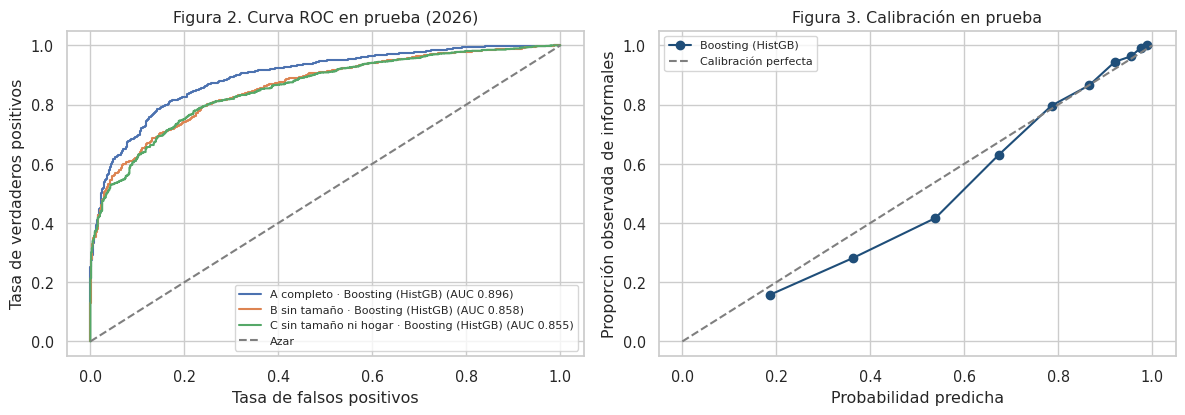

Calibración del modelo principal en prueba (deciles de probabilidad predicha):


,Prob. media predicha,Proporción observada
0,0.186,0.157
1,0.364,0.282
2,0.538,0.417
3,0.673,0.630
4,0.786,0.796
5,0.866,0.865
6,0.920,0.944
7,0.954,0.963
8,0.975,0.991
9,0.988,1.000


In [13]:
PRIN = ("A completo", FINALISTA["A completo"]); thr = UMBRAL[PRIN]; pte = PTE[PRIN]
fig, ax = plt.subplots(1, 2, figsize=(12,4.3))
for (cj,mn) in [(c,FINALISTA[c]) for c in CONJUNTOS]:
    fpr,tpr,_ = roc_curve(yte, PTE[(cj,mn)]); ax[0].plot(fpr,tpr,label=f"{cj} · {mn} (AUC {roc_auc_score(yte,PTE[(cj,mn)]):.3f})")
ax[0].plot([0,1],[0,1],"--",color=GRIS,label="Azar"); ax[0].set_title("Figura 2. Curva ROC en prueba (2026)")
ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos"); ax[0].legend(fontsize=8)
fr,mp = calibration_curve(yte, pte, n_bins=10, strategy="quantile"); ax[1].plot(mp,fr,"o-",color=AZUL,label=PRIN[1]); ax[1].plot([0,1],[0,1],"--",color=GRIS,label="Calibración perfecta")
ax[1].set_title("Figura 3. Calibración en prueba"); ax[1].set_xlabel("Probabilidad predicha"); ax[1].set_ylabel("Proporción observada de informales"); ax[1].legend(fontsize=8)
plt.tight_layout(); guardar_figura(RUTA_FIG, "fig2_3_roc_calibracion"); plt.show()
print("Calibración del modelo principal en prueba (deciles de probabilidad predicha):")
display(pd.DataFrame({"Prob. media predicha": mp, "Proporción observada": fr}).round(3))

**Interpretación.** El modelo completo domina a B y C en toda la curva ROC, sobre todo con tasas bajas de falsos positivos, y las curvas de B y C casi coinciden (el hogar aporta poco). Con el umbral 0,77 domina el error de **falsos negativos**: 377 informales clasificados como formales frente a 79 falsos positivos (1.144 verdaderos positivos y 559 verdaderos negativos). El umbral alto compensa la prevalencia de 70 % a costa de no detectar a 1 de cada 4 informales; si el uso fuera focalizar programas, el umbral debería bajar, y esa es una decisión de política, no estadística. Las probabilidades están bien calibradas desde ≈ 0,75, pero en el tramo medio **sobrestiman** la informalidad: el decil con probabilidad media 0,54 resulta 42 % informal y el de 0,36, 28 % (hasta ≈ 12 puntos). Esto precisa el rechazo de Hosmer-Lemeshow de la Fase 2: el desajuste se concentra en probabilidades intermedias. Con Brier 0,119 (frente a 0,208 de la clase mayoritaria) las probabilidades son útiles, pero para estimar tasas agregadas conviene recalibrarlas (isotónica o Platt) con datos de validación.

## 9. Análisis de errores

In [14]:
E = te.copy(); E["p"] = pte; E["pred"] = (pte>=thr).astype(int); E["y"] = yte.values; E["error"] = (E.pred!=E.y).astype(int)
E["abs_err"] = (E.y - E.p).abs()
print("Los 15 casos peor predichos (error probabilístico máximo):")
mostrar = [c for c in ["y","p","tam_cat","ocup_grp","educ_nivel","entorno_informal","edad","mujer","rural","rama","periodo"] if c in E.columns]
display(E.sort_values("abs_err", ascending=False).head(15)[mostrar].round(3))
def tasa_error(col):
    g = E.groupby(col).agg(n=("error","size"), error=("error","mean"), FN=("y", lambda s: ((s==1)&(E.loc[s.index,"pred"]==0)).sum()),
                           FP=("y", lambda s: ((s==0)&(E.loc[s.index,"pred"]==1)).sum()))
    return g.sort_values("error", ascending=False).round(3)
for c in ["ocup_grp","tam_cat","educ_nivel","periodo"]:
    print(f"\nError por {c}:"); display(tasa_error(c))

Los 15 casos peor predichos (error probabilístico máximo):


,y,p,tam_cat,ocup_grp,educ_nivel,entorno_informal,edad,mujer,rural,rama,periodo
1350,0,0.972,2 a 5,Servicios y ventas,Media (10-12),Todos,19.0,0.0,1.0,5.0,2026-T2
1999,0,0.968,2 a 5,Operarios y artesanos,Media (10-12),Todos,21.0,0.0,0.0,5.0,2026-T2
1306,0,0.966,Sin tamaño válido (-1),No calificados,Superior (13+),Mayoria,26.0,1.0,0.0,8.0,2026-T2
494,0,0.966,2 a 5,Operarios y artesanos,Media (10-12),Sin otros ocupados,22.0,0.0,0.0,4.0,2026-T1
1616,0,0.959,2 a 5,Servicios y ventas,Media (10-12),Minoria,20.0,1.0,0.0,5.0,2026-T2
1016,0,0.954,2 a 5,Servicios y ventas,Media (10-12),Todos,21.0,1.0,0.0,5.0,2026-T1
729,0,0.950,2 a 5,Operarios y artesanos,EEB (6-9),Todos,24.0,0.0,1.0,4.0,2026-T1
1835,0,0.946,Solo,Técnicos,Superior (13+),Todos,26.0,0.0,0.0,8.0,2026-T2
1490,0,0.946,2 a 5,No calificados,Media (10-12),Todos,22.0,1.0,1.0,5.0,2026-T2
1024,0,0.943,2 a 5,Servicios y ventas,Media (10-12),Todos,21.0,0.0,0.0,5.0,2026-T1



Error por ocup_grp:


,n,error,FN,FP
ocup_grp,,,,
Directivos y profesionales,129,0.333,42,1
Oficinistas,208,0.322,66,1
Operadores de máquinas,118,0.322,34,4
Técnicos,209,0.287,50,10
Operarios y artesanos,283,0.212,39,21
Servicios y ventas,581,0.210,91,31
No calificados,606,0.106,53,11
Otras (cód. 6 y 10),25,0.080,2,0



Error por tam_cat:


,n,error,FN,FP
tam_cat,,,,
11 a 20,135,0.385,48,4
6 a 10,247,0.385,86,9
21 a 30,78,0.321,25,0
31 a 50,85,0.306,25,1
Código 11 (sin etiqueta),121,0.281,32,2
101 a 500,112,0.223,25,0
51 a 100,89,0.202,18,0
Solo,380,0.192,56,17
Más de 500,40,0.175,7,0



Error por educ_nivel:


,n,error,FN,FP
educ_nivel,,,,
Superior (13+),777,0.293,201,27
Media (10-12),1014,0.190,152,41
EEB (6-9),324,0.108,24,11
Primaria incompleta (0-5),44,0.000,0,0



Error por periodo:


,n,error,FN,FP
periodo,,,,
2026-T1,1078,0.219,198,38
2026-T2,1081,0.204,179,41


**Interpretación.** El modelo falla sobre todo con **informales que tienen rasgos de empleo formal**: los tramos de 6 a 50 personas tienen errores de 31 % a 39 %, casi solo falsos negativos; lo mismo ocurre en ocupaciones calificadas (directivos y profesionales 33 %, oficinistas 32 %) y con educación superior, que reúne 201 de los 377 falsos negativos. En los extremos el modelo acierta más («2 a 5»: 15 %; «Solo»: 19 %; «Más de 500»: 18 %). De los 15 casos peor predichos, 14 son formales con probabilidad 0,93 a 0,97, casi todos en establecimientos de 2 a 5 personas; el restante es un informal en una empresa de más de 500 personas con probabilidad 0,07: perfiles donde el tamaño «miente» y ninguna otra variable lo corrige. La categoría «Sin tamaño válido (−1)» se acierta en 222 de 223 casos, señal de que ese código está ligado a cómo el INE construye la variable objetivo (circularidad). No hay deriva dentro de la ventana de prueba: el error es 21,9 % en 2026-T1 y 20,4 % en 2026-T2.

## 10. Interpretación del modelo y contraste con las fases previas

Mayores coeficientes de la logística (numéricas estandarizadas; categóricas en one-hot completo):


,variable,coef,OR (por 1 DE / vs. categoría omitida)
54,cat__tam_cat_Sin tamaño válido (-1),2.587,13.286
53,cat__tam_cat_Más de 500,-1.618,0.198
47,cat__tam_cat_2 a 5,1.586,4.885
45,cat__tam_cat_101 a 500,-1.473,0.229
55,cat__tam_cat_Solo,1.110,3.034
50,cat__tam_cat_51 a 100,-0.958,0.383
24,cat__rama_4.0,0.806,2.240
19,cat__ocup_grp_Otras (cód. 6 y 10),-0.737,0.478
14,cat__ocup_grp_Directivos y profesionales,-0.672,0.511
49,cat__tam_cat_31 a 50,-0.631,0.532


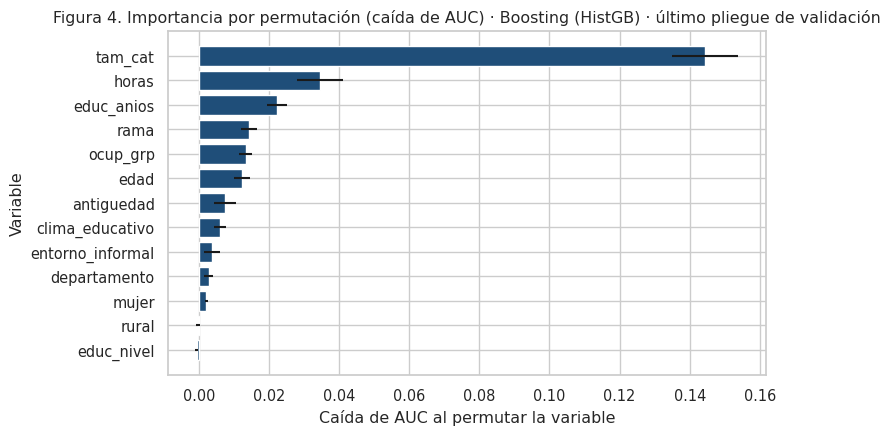

Caída media de AUC al permutar cada variable (20 repeticiones):


,Caída de AUC
tam_cat,0.1443
horas,0.0346
educ_anios,0.0222
rama,0.0143
ocup_grp,0.0134
edad,0.0123
antiguedad,0.0076
clima_educativo,0.0060
entorno_informal,0.0038
departamento,0.0028


In [15]:
# (a) Regresión logística del conjunto A: razones de odds (comparables con la Fase 2)
lr = GS[("A completo","Logística")].best_estimator_
nom = lr.named_steps["pre"].get_feature_names_out(); coef = lr.named_steps["clf"].coef_[0]
OR = pd.DataFrame({"variable": nom, "coef": coef, "OR (por 1 DE / vs. categoría omitida)": np.exp(coef)}).sort_values("coef", key=abs, ascending=False)
print("Mayores coeficientes de la logística (numéricas estandarizadas; categóricas en one-hot completo):"); display(OR.head(15).round(3))

# (b) Importancia por permutación del finalista A, medida en el último pliegue de validación (sin usar prueba)
a,b = FOLDS[-1]; num,cat = CONJUNTOS["A completo"]; Xa = tr[num+cat]
m = clone(GS[PRIN].best_estimator_).fit(Xa.iloc[a], ytr.iloc[a])
pi = permutation_importance(m, Xa.iloc[b], ytr.iloc[b], scoring="roc_auc", n_repeats=20, random_state=SEMILLA, n_jobs=-1)
IMP = pd.Series(pi.importances_mean, index=Xa.columns).sort_values()
fig, ax = plt.subplots(figsize=(8,4.5)); ax.barh(IMP.index, IMP.values, xerr=pd.Series(pi.importances_std, index=Xa.columns)[IMP.index], color=AZUL)
ax.set_title(f"Figura 4. Importancia por permutación (caída de AUC) · {PRIN[1]} · último pliegue de validación")
ax.set_xlabel("Caída de AUC al permutar la variable"); ax.set_ylabel("Variable"); plt.tight_layout(); guardar_figura(RUTA_FIG, "fig4_importancia_permutacion"); plt.show()
print("Caída media de AUC al permutar cada variable (20 repeticiones):")
display(IMP.sort_values(ascending=False).round(4).to_frame("Caída de AUC"))

**Interpretación del modelo.** El tamaño del establecimiento es, por lejos, la variable más predictiva: al permutarlo el AUC cae 0,144, cuatro veces más que las horas trabajadas (0,035) y los años de estudio (0,022); rama, ocupación y edad quedan en 0,012–0,014; antigüedad, clima educativo y entorno informal por debajo de 0,01, y sexo, área y nivel educativo en ≈ 0 (el nivel educativo no suma porque los años de estudio ya llevan esa información). En la logística, siete de los diez mayores coeficientes son tramos de tamaño (OR 13,3 para «Sin tamaño válido», 4,9 para «2 a 5», 3,0 para «Solo» y 0,20 para «Más de 500»). Como usa one-hot completo con regularización L2, cada OR compara la categoría con el promedio regularizado: sirven para ordenar efectos, no para leerlos como los OR de la Fase 2.

**Contraste con la Fase 2:**

| Hallazgo previo | Fase 1-2 | ¿Coincide en el modelo? |
|---|---|---|
| El puesto (tamaño y ocupación) es el correlato más fuerte | V = 0,50 (H1) | **Sí.** Primera variable por lejos (caída de AUC 0,144); quitarla cuesta 0,038 de AUC en prueba |
| La educación conserva asociación moderada | OR 9,4 / 3,7 / 1,6 (H2) | **Sí, moderada.** Años de estudio, tercera variable (0,022) |
| El entorno informal del hogar aporta poco poder discriminante | ΔAUC = 0,005 (H3) | **Sí.** Importancia 0,004; pasar de B a C cuesta 0,003 de AUC |
| Sexo y área rural: asociaciones pequeñas | OR ≈ 1,2 | **Sí.** Importancia ≈ 0 |

El modelo reproduce fuera de la muestra el orden hallado con inferencia: **puesto > educación > entorno del hogar > sexo y área**. Recordar: importancia predictiva **no** es causalidad.

## 11. Equidad: desempeño por sexo y área

In [16]:
def por_grupo(col, etq):
    r = []
    for v,g in E.groupby(col):
        tn,fp,fn,tp = confusion_matrix(g.y, g.pred, labels=[0,1]).ravel()
        r.append({"grupo": etq[v], "n": len(g), "% informal real": g.y.mean(), "% predicho informal": g.pred.mean(),
                  "Exhaustividad (TPR)": tp/(tp+fn) if tp+fn else np.nan, "Tasa falsos positivos": fp/(fp+tn) if fp+tn else np.nan,
                  "AUC": roc_auc_score(g.y, g.p) if g.y.nunique()>1 else np.nan})
    return pd.DataFrame(r).round(3)
display(por_grupo("mujer", {0.0:"Hombre",1.0:"Mujer"})); display(por_grupo("rural", {0.0:"Urbano",1.0:"Rural"}))

,grupo,n,% informal real,% predicho informal,Exhaustividad (TPR),Tasa falsos positivos,AUC
0,Hombre,1131,0.682,0.544,0.734,0.136,0.882
1,Mujer,1028,0.730,0.591,0.771,0.108,0.911


,grupo,n,% informal real,% predicho informal,Exhaustividad (TPR),Tasa falsos positivos,AUC
0,Urbano,1483,0.672,0.510,0.700,0.123,0.877
1,Rural,676,0.777,0.689,0.851,0.126,0.932


**Interpretación.** La capacidad de ordenar casos es alta en los cuatro grupos (AUC 0,882 en hombres, 0,911 en mujeres, 0,877 urbano y 0,932 rural) y la tasa de falsos positivos no difiere más de 3 puntos. La brecha está en la **exhaustividad**: el modelo detecta al 85 % de los informales rurales y solo al 70 % de los urbanos, y subestima la informalidad en todos los grupos (predice 51–69 % frente a 67–78 % reales). Si se usara para asignar programas, los jóvenes urbanos informales quedarían subrepresentados; cualquier uso exige revisar el umbral por grupo o, al menos, monitorear esta brecha.

## 12. Serialización y reproducibilidad

In [17]:
num,cat = CONJUNTOS["A completo"]
BUNDLE = {"modelo": GS[PRIN].best_estimator_, "umbral": UMBRAL[PRIN], "variables": num+cat, "conjunto": "A completo",
          "algoritmo": PRIN[1], "sklearn": sklearn.__version__, "semilla": SEMILLA, "entrenado_con": "2024-2025 (sin hogares de 2026)"}
joblib.dump(BUNDLE, RUTA_MOD/"modelo_informalidad.joblib")
# Variantes de sensibilidad (sin tamaño / desplegable)
for cj in ["B sin tamaño","C sin tamaño ni hogar"]:
    n,c = CONJUNTOS[cj]; k = (cj, FINALISTA[cj])
    joblib.dump({"modelo": GS[k].best_estimator_, "umbral": UMBRAL[k], "variables": n+c, "conjunto": cj, "algoritmo": k[1],
                 "sklearn": sklearn.__version__, "semilla": SEMILLA}, RUTA_MOD/f"modelo_informalidad_{cj[0]}.joblib")
TEST.to_csv(RUTA_OUT/"tabla_resultados_fase3.csv", index=False); TAB_CV.to_csv(RUTA_OUT/"tabla_validacion_fase3.csv", index=False)

# Prueba del script de inferencia sobre una muestra
from predict import predecir   # src/predict.py
demo = predecir(RUTA_MOD/"modelo_informalidad.joblib", df_raw.head(5)); display(demo)


,prob_informal,pred_informal
0,0.540722,0
1,0.738606,0
2,0.213701,0
3,0.198974,0
4,0.175778,0


## 13. Conclusión de la Fase 3
1. **Desempeño y línea base.** El modelo principal (HistGradientBoosting, conjunto A) obtiene en 2026 AUC 0,896, exactitud balanceada 0,814 y F1 0,834, frente a 0,687 de exactitud balanceada de la regla de tamaño y 0,500 de la clase mayoritaria. La brecha entrenamiento–validación es moderada (0,039) y la prueba no muestra deterioro respecto de la validación (0,882 → 0,896).
2. **Variables más predictivas.** Tamaño del establecimiento (caída de AUC 0,144), horas y años de estudio; el orden coincide con las Fases 1-2. Sin `tam_empresa` el AUC baja a 0,858 y sin el hogar, a 0,855: la posible circularidad no explica todo el desempeño y el hogar aporta poco fuera de la muestra.
3. **Condiciones de uso.** Útil para estimaciones agregadas de informalidad juvenil entre rondas de la encuesta (previa recalibración) y para focalización exploratoria. No útil para decisiones individuales automáticas (inspecciones, elegibilidad) ni para inferir causas.
4. **Limitaciones de generalización.** Una sola ventana de prueba (2026-T1/T2); sin identificador longitudinal ni estratos/UPM (las métricas valen para la muestra); calibración imperfecta en probabilidades intermedias; ingresos excluidos; la etiqueta es la definición administrativa del INE.
5. **Riesgos éticos y de sesgo.** Detección desigual por área (85 % rural vs 70 % urbano); riesgo de estigmatizar a trabajadores de microempresas u ocupaciones específicas si se usara a nivel individual.
6. **Respuesta final a la pregunta de la Fase 1.** La informalidad de los jóvenes ocupados no agropecuarios se asocia, en este orden, con el puesto de trabajo (tamaño y ocupación), la educación, el entorno informal del hogar y, en menor medida, el sexo y el área. Ese orden se mantiene como orden de poder predictivo en un período no observado, y con información de una encuesta de hogares se ordenan bien 9 de cada 10 pares informal–formal (AUC 0,896).

---
**Fin del cuaderno 03.** Tablas en `output/fase3/`, figuras en `output/fase3/figuras/` y modelos serializados en
`output/fase3/modelos/`. Para aplicar el modelo a datos nuevos:
`python src/predict.py --modelo output/fase3/modelos/modelo_informalidad.joblib --entrada nuevos.csv --salida pred.csv`.
Para exportar este cuaderno a HTML, ver la sección *Ejecución* del `README.md`.